In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import nfl_data_py as nfl

# Define the years to import
yrs = range(2017, 2020)
#yrs = 2022

# Play-by-Play Data
pbp_data = nfl.import_pbp_data(years=yrs)

# Player Stats
#player_stats = nfl.import_seasonal_data(years=yrs, s_type='ALL')

# Weekly Rosters
weekly_rosters = nfl.import_weekly_rosters(years=yrs)

# Schedules
#schedules = nfl.import_schedules(years=yrs)

# Injuries
injuries = nfl.import_injuries(years=yrs)

# Draft Data
#draft_data = nfl.import_draft_picks(years=yrs)

# Combine Data
#combine_data = nfl.import_combine_data(years=yrs)

# Weekly Fantasy Data
#weekly_fantasy_data = nfl.import_weekly_data(years=yrs)

# Officiating Data
#officiating_data = nfl.import_officials(years=yrs)

# Betting Lines
#betting_lines = nfl.import_sc_lines(yrs)

# Depth Charts
depth_charts = nfl.import_depth_charts(years=yrs)

# Next Gen Stats
#next_gen_stats = nfl.import_ngs_data(years=yrs, stat_type='passing')

<urlopen error [WinError 10060] A connection attempt failed because the connected party did not properly respond after a period of time, or established connection failed because connected host has failed to respond>
Data not available for 2017
2018 done.
2019 done.
Downcasting floats.


In [3]:
# 'C:\Users\Jack\Documents\GitHub\FFInsights\context_preds.csv'
context_forecast_df = pd.read_csv(r'C:\Users\Jack\Documents\GitHub\FFInsights\context_preds.csv')
context_forecast_df.head()

,game_id,play_id,epa,expected_epa,shrinked_preds,residual_epa,variance_encoder,pressure_prob,predicted_rush_yards,predicted_yac,completion_prob,pass_breakup_prob,predicted_time_to_throw
0,2016_01_NE_ARI,241.0,-0.564257,-0.258300,-0.012915,-0.551342,1.831828,0.393293,NaN,3.306424,0.410585,0.420536,1.896610
1,2016_01_NE_ARI,263.0,-0.720176,-0.076579,-0.003829,-0.716347,0.952143,NaN,5.093922,NaN,NaN,NaN,NaN
2,2016_01_NE_ARI,284.0,1.971302,-0.302733,-0.015137,1.986439,4.268127,0.450279,NaN,2.473998,0.358089,0.502799,2.254585
3,2016_01_NE_ARI,340.0,1.677589,0.021747,0.001087,1.676502,1.639341,0.328465,NaN,3.461304,0.549997,0.404134,2.092072
4,2016_01_NE_ARI,365.0,-0.416293,-0.142279,-0.007114,-0.409179,0.693973,NaN,4.067931,NaN,NaN,NaN,NaN


In [4]:
# 'c:\\Users\\Jack\\Documents\\GitHub\\FFInsights\\data\\voe_weekly_data.xlsx'
voe_weekly_data = pd.read_excel(r'C:\Users\Jack\Documents\GitHub\FFInsights\data\voe_weekly_data.xlsx')
voe_weekly_data.head()

,player_id,season,week,play_type,realized_voe,expected_voe,residual_epa,ones,variance_encoder,fantasy_points_ppr,future_fantasy_points,future_realized_voe,future_expected_voe,future_residual_epa,gsis_id,position_label,full_name,formation,club_code
0,00-0019596,2016,6,pass,-7.394134,0.363183,18.5,38,93.7,27.24,18.18,-12.224223,0.005690,8.8,00-0019596,QB1,Tom Brady,Offense,NE
1,00-0019596,2016,6,run,-3.830804,-0.091213,-2.4,23,28.3,27.24,18.18,-4.970864,0.580348,4.8,00-0019596,QB1,Tom Brady,Offense,NE
2,00-0019596,2016,7,pass,-12.224223,0.005690,8.8,26,90.1,18.18,30.10,-25.170766,1.039892,21.4,00-0019596,QB1,Tom Brady,Offense,NE
3,00-0019596,2016,7,run,-4.970864,0.580348,4.8,28,21.8,18.18,30.10,-10.059279,0.297272,-1.8,00-0019596,QB1,Tom Brady,Offense,NE
4,00-0019596,2016,8,pass,-25.170766,1.039892,21.4,37,96.1,30.10,11.34,-9.197486,0.837344,7.4,00-0019596,QB1,Tom Brady,Offense,NE


In [5]:
injuries.head()

,season,game_type,team,week,gsis_id,position,full_name,first_name,last_name,report_primary_injury,report_secondary_injury,report_status,practice_primary_injury,practice_secondary_injury,practice_status,date_modified
0,2017.0,REG,ARI,1.0,00-0022921,WR,Larry Fitzgerald,Larry,Fitzgerald,None,None,None,Not Injury Related,None,Full Participation in Practice,2017-09-08 12:44:25+00:00
1,2017.0,REG,ARI,1.0,00-0021429,QB,Carson Palmer,Carson,Palmer,None,None,None,Not Injury Related,None,Full Participation in Practice,2017-09-08 12:44:25+00:00
2,2017.0,REG,ARI,1.0,00-0031366,LB,Deone Bucannon,Deone,Bucannon,Ankle,None,Out,Ankle,None,Did Not Participate In Practice,2017-09-08 12:44:44+00:00
3,2017.0,REG,ARI,1.0,00-0027869,G,Mike Iupati,Mike,Iupati,Tricep,None,Questionable,Tricep,None,Limited Participation in Practice,2017-09-08 12:44:35+00:00
4,2017.0,REG,ARI,1.0,00-0032761,DT,Robert Nkemdiche,Robert,Nkemdiche,Calf,None,Questionable,Calf,None,Limited Participation in Practice,2017-09-08 12:44:35+00:00


In [6]:
def pivot_wide_both_sides(data):
    import warnings
    warnings.filterwarnings('ignore')

    # Filter for valid play types
    data = data[data['play_type'].isin(['run', 'pass'])].copy()

    # Sort for consistency
    data = data.sort_values(['game_id', 'play_id'])

    # Helper function to expand player columns
    def expand_player_col(df, col_name):
        side = col_name.split('_')[0]  # offense or defense

        # Fill missing with empty string to allow split
        players_split = df[col_name].fillna('').str.split(';')

        # Pad each list to exactly 11 players (or truncate)
        players_list = players_split.apply(lambda lst: (lst + [None]*11)[:11])

        # Convert to DataFrame
        players_df = pd.DataFrame(players_list.tolist(), columns=[f'{side}_player_{i+1}' for i in range(11)])

        return players_df

    # Expand offense and defense player columns
    offense_wide = expand_player_col(data, 'offense_players')
    defense_wide = expand_player_col(data, 'defense_players')

    # Concatenate expanded columns with the original DataFrame
    pbp_wide = pd.concat([data.reset_index(drop=True), offense_wide, defense_wide], axis=1)

    # Drop potential duplicates
    pbp_wide = pbp_wide.drop_duplicates(subset=['game_id', 'play_id'])

    # Drop rows with NaN in offense_players or defense_players
    pbp_wide = pbp_wide.dropna(subset=['offense_players', 'defense_players'])

    return pbp_wide

In [7]:
def clean_depth_charts(depth_charts):
    # Remove duplicates on season, club_code, week, gsis_id
    depth_charts_copy = depth_charts.drop_duplicates(subset=['season', 'club_code', 'week', 'gsis_id'])
    depth_charts_copy = depth_charts_copy[depth_charts_copy['formation'].str.contains('Offense|Defense', regex=True)].copy()

    # Replace 'T' and 'G' in 'position' with the value from 'depth_position'
    depth_charts_copy['position'] = np.where(
        depth_charts_copy['position'].isin(['T', 'G']),
        depth_charts_copy['depth_position'],
        depth_charts_copy['position']
    )

    # Replace 'LOT' in 'position'
    depth_charts_copy['position'] = np.where(
        depth_charts_copy['position'].isin(['LOT']),
        'LT',
        depth_charts_copy['position']
    )

    # Replace 'ROT' in 'position'
    depth_charts_copy['position'] = np.where(
        depth_charts_copy['position'].isin(['ROT']),
        'RT',
        depth_charts_copy['position']
    )

    # Replace 'RDE' and 'LDE'
    depth_charts_copy['position'] = np.where(
        depth_charts_copy['position'].isin(['RDE', 'LDE']),
        'DE',
        depth_charts_copy['position']
    )   

    # Replace 'RDT' and 'LDT'
    depth_charts_copy['position'] = np.where(
        depth_charts_copy['position'].isin(['RDT', 'LDT']),
        'DT',
        depth_charts_copy['position']
    )   
    
    # Replace 'DB' with 'CB'
    depth_charts_copy['position'] = np.where(
        depth_charts_copy['position'].isin(['LB']),
        'MLB',
        depth_charts_copy['position']
    )

    # Replace 'K', 'P', 'LS'
    depth_charts_copy['position'] = np.where(
        depth_charts_copy['position'].isin(["\n ", 'K', 'P', 'LS']),
        'special',
        depth_charts_copy['position']
    )

    # Replace 'DB' with 'CB'
    depth_charts_copy['position'] = np.where(
        depth_charts_copy['position'].isin(['DB']),
        'CB',
        depth_charts_copy['position']
    )

    # Replace '\n'
    depth_charts_copy['position'] = np.where(
        depth_charts_copy['position'].str.contains(' '),
        'special',
        depth_charts_copy['position']
    )

    # Replace 'SBBYE'
    depth_charts_copy['week'] = np.where(
        depth_charts_copy['week'].isna(),
        '23',
        depth_charts_copy['week']
    )

    # Seniority counter
    depth_charts_copy['seniority'] = depth_charts_copy.groupby(['gsis_id']).cumcount() + 1

    # Cumulative sum of depth_team per gsis_team
    depth_charts_copy['depth_team'] = depth_charts_copy['depth_team'].astype(int)
    depth_charts_copy['depth_team_sum'] = depth_charts_copy.groupby(['gsis_id'])['depth_team'].cumsum()

    # Cumulative mean of depth_team per gsis_team
    depth_charts_copy['depth_team_mean'] = depth_charts_copy['depth_team_sum'] / depth_charts_copy['seniority']

    # Sort by season, club_code, week, position, depth_team_mean
    depth_charts_copy = depth_charts_copy.sort_values(['depth_team_mean'], ascending=True)

    # Cumulative count of season, week, club_team, position
    depth_charts_copy['depth_team_estimator'] = depth_charts_copy.groupby(['season', 'week', 'club_code', 'position']).cumcount() + 1
    
    #depth_charts_copy['depth_team_estimator'] = depth_charts_copy['depth_team_estimator'].astype(int)
    depth_charts_copy['depth_team_estimator'] = depth_charts_copy['depth_team_estimator'].astype(str)

    # Define position_label
    depth_charts_copy['position_label'] = depth_charts_copy['position'] + depth_charts_copy['depth_team_estimator'].astype(str)
    depth_charts_copy['season'] = depth_charts_copy['season'].astype(int)
    depth_charts_copy['gsis_id'] = depth_charts_copy['gsis_id'].astype(str)
    depth_charts_copy['week'] = depth_charts_copy['week'].astype(str).str.replace('.0', '', regex=False).astype(int)

    return depth_charts_copy

In [8]:
def pivot_long_both_sides(pbp_wide, depth_charts):
    import warnings
    warnings.filterwarnings('ignore')
    
    # Clean depth charts
    depth_charts_clean = clean_depth_charts(depth_charts)
    
    # Combine offense and defense player columns into long format
    long_df = pd.wide_to_long(
        pbp_wide.reset_index(),
        stubnames=['offense_player', 'defense_player'],
        i=['index'],  # preserves play-wise indexing
        j='player_number',
        sep='_',
        suffix='\\d+'
    ).reset_index()
    
    # Stack both sides
    offense_df = long_df[['game_id', 'play_id', 'offense_player', 'player_number', 'season', 'week']].copy()
    offense_df.rename(columns={'offense_player': 'player_id'}, inplace=True)

    defense_df = long_df[['game_id', 'play_id', 'defense_player', 'player_number', 'season', 'week']].copy()
    defense_df.rename(columns={'defense_player': 'player_id'}, inplace=True)
    
    all_long = pd.concat([offense_df, defense_df], ignore_index=True)

    # Deduplicate depth_charts BEFORE merge to prevent cartesian product
    depth_charts_dedup = depth_charts_clean.drop_duplicates(
        subset=['season', 'week', 'gsis_id']
    )[['season', 'week', 'gsis_id', 'position_label', 'full_name']]

    # Merge with depth charts
    all_long['player_id'] = all_long['player_id'].astype(str).str.strip()
    depth_charts_dedup['gsis_id'] = depth_charts_dedup['gsis_id'].astype(str).str.strip()
    merged = all_long.merge(
        depth_charts_dedup,
        left_on=['season', 'week', 'player_id'],
        right_on=['season', 'week', 'gsis_id'],
        how='left'
    )

    # Drop unnecessary
    merged = merged.drop(columns=['gsis_id'])

    # Replace the dropna with a fillna for debugging
    merged['position_label'] = merged['position_label'].fillna('special')

    # Filter nulls
    merged = merged.dropna(subset=['player_id', 'position_label'])

    # Deduplicate on the final result
    merged = merged.drop_duplicates(subset=['game_id', 'play_id', 'player_id'])

    return merged.sort_values(['game_id', 'play_id'])

# Ideas and Structure

🔹 1. Workload & Exposure

These measure how much physical strain the body is under from sheer time on the field.
Cumulative snaps (offense/defense/ST splits).
Snaps per season / per game (workload intensity).
Total seconds played (exposure to strain).
High-intensity play count: plays requiring sprinting, heavy blocking, or contact (using PBP classification like rush attempts, blitzes, deep routes).
Bye week utilization: whether rest weeks align with workload spikes (a rest/recovery proxy).
Short-week games played (Thursday games = less recovery).

🔹 2. Contact & Physical Stress

Fatigue isn’t just playing time — it’s how hard those plays were on the body.
Tackles absorbed in bounds (already on your list).
Tackles in the middle of field (higher contact probability).
Yards after contact taken (RBs/WRs getting hit multiple times per play).
Blocking snaps (linemen / TEs: repeated collisions).
Hits taken by QBs (sacks + knockdowns + hurries).
Special teams collisions (kick/punt returns have higher-speed impacts).
Cumulative contact events (proxy from tackles + sacks + carries).

🔹 3. Injury & Recovery

Direct health-related indicators of wear-and-tear.
Injury history count (games missed, # of injuries).
Injury severity index (weighted by type: concussions, ACL > minor sprains).
Average recovery time (weeks missed per injury).
Injury recurrence risk (repeated injuries to same body part).
Injury-adjusted age (biological wear > chronological age, proxy by missed games).

🔹 4. Biomechanical & Physiological Indicators

Long-term body composition and strain.
BMI over time (already noted).
Weight fluctuation rate (rapid shifts stress joints).
Speed decline (40-yard dash equivalent from NextGen Stats top speed).
Acceleration decline (burst measures).
Explosiveness proxies (YAC, air yards, breakaway %).

🔹 5. Contextual Stressors

Fatigue can also be driven by external factors.
Travel distance per season (miles traveled = circadian & recovery stress).
Play style scheme (run-heavy schemes stress RBs more, vertical passing exposes QBs/WRs to hits).
Weather exposure (cold-weather games = joint strain, turf fields = higher injury rates).
Team depth / rotation (starters with low backup usage have higher fatigue load).

🔹 6. Derived Career Fatigue Metrics

We can combine the above into cumulative “wear” features:
Career Contact Index (CCI) = tackles absorbed + sacks + carries + blocks.
Fatigue Load per Season = snaps × contact intensity.
Wear/Recovery Ratio = workload divided by recovery opportunities (bye weeks, offseason injuries).
Time-weighted workload (e.g., last 2–3 years weighted heavier than rookie years).
Expected career workload vs. actual (compare to positional averages).

In [9]:
game_info = [
    'play_id', 'game_id', 'old_game_id_x', 'home_team', 'away_team', 'season_type', 'week', 
    'game_date', 'total_home_score', 'total_away_score', 'posteam', 'posteam_type', 'defteam', 
    'location', 'stadium', 'weather', 'temp', 'wind', 'roof', 'surface', 'home_coach', 'away_coach', 
    'stadium_id', 'game_stadium', 'away_score', 'home_score', 'result', 'total', 'spread_line', 
    'total_line', 'div_game', 'home_opening_kickoff', 'nflverse_game_id', 'old_game_id_y'
]

drive_info = [
    'drive', 'drive_real_start_time', 'drive_play_count', 'drive_time_of_possession', 
    'drive_first_downs', 'drive_inside20', 'drive_ended_with_score', 'drive_quarter_start', 
    'drive_quarter_end', 'drive_yards_penalized', 'drive_start_transition', 'drive_end_transition', 
    'drive_game_clock_start', 'drive_game_clock_end', 'drive_start_yard_line', 'drive_end_yard_line', 
    'drive_play_id_started', 'drive_play_id_ended', 'fixed_drive', 'fixed_drive_result'
]

play_info = [
    'quarter_seconds_remaining', 'half_seconds_remaining', 'game_seconds_remaining', 'game_half', 
    'quarter_end', 'sp', 'qtr', 'down', 'goal_to_go', 'time', 'yrdln', 'ydstogo', 'ydsnet', 'desc', 
    'play_type', 'yards_gained', 'shotgun', 'no_huddle', 'qb_dropback', 'qb_kneel', 'qb_spike', 
    'qb_scramble', 'pass_length', 'pass_location', 'air_yards', 'yards_after_catch', 'run_location', 
    'run_gap', 'field_goal_result', 'kick_distance', 'extra_point_result', 'two_point_conv_result', 
    'home_timeouts_remaining', 'away_timeouts_remaining', 'timeout', 'timeout_team', 'td_team', 
    'td_player_name', 'td_player_id', 'posteam_timeouts_remaining', 'defteam_timeouts_remaining', 
    'score_differential', 'posteam_score', 'defteam_score', 'posteam_score_post', 'defteam_score_post', 
    'score_differential_post', 'no_score_prob', 'opp_fg_prob', 'opp_safety_prob', 'opp_td_prob', 
    'fg_prob', 'safety_prob', 'td_prob', 'extra_point_prob', 'two_point_conversion_prob', 'ep', 'epa', 
    'total_home_epa', 'total_away_epa', 'total_home_rush_epa', 'total_away_rush_epa', 
    'total_home_pass_epa', 'total_away_pass_epa', 'air_epa', 'yac_epa', 'comp_air_epa', 'comp_yac_epa', 
    'total_home_comp_air_epa', 'total_away_comp_air_epa', 'total_home_comp_yac_epa', 
    'total_away_comp_yac_epa', 'total_home_raw_air_epa', 'total_away_raw_air_epa', 
    'total_home_raw_yac_epa', 'total_away_raw_yac_epa', 'wp', 'def_wp', 'home_wp', 'away_wp', 'wpa', 
    'vegas_wpa', 'vegas_home_wpa', 'home_wp_post', 'away_wp_post', 'vegas_wp', 'vegas_home_wp', 
    'total_home_rush_wpa', 'total_away_rush_wpa', 'total_home_pass_wpa', 'total_away_pass_wpa', 
    'air_wpa', 'yac_wpa', 'comp_air_wpa', 'comp_yac_wpa', 'total_home_comp_air_wpa', 
    'total_away_comp_air_wpa', 'total_home_comp_yac_wpa', 'total_away_comp_yac_wpa', 
    'total_home_raw_air_wpa', 'total_away_raw_air_wpa', 'total_home_raw_yac_wpa', 'total_away_raw_yac_wpa'
]

player_actions = [
    'rush_attempt', 'pass_attempt', 'sack', 'qb_hit', 'qb_hit_1_player_id', 'qb_hit_1_player_name', 
    'qb_hit_2_player_id', 'qb_hit_2_player_name', 'solo_tackle', 'assist_tackle', 'tackled_for_loss', 
    'tackle_for_loss_1_player_id', 'tackle_for_loss_1_player_name', 'tackle_for_loss_2_player_id', 
    'tackle_for_loss_2_player_name', 'forced_fumble_player_1_team', 'forced_fumble_player_1_player_id', 
    'forced_fumble_player_1_player_name', 'forced_fumble_player_2_team', 'forced_fumble_player_2_player_id', 
    'forced_fumble_player_2_player_name', 'fumble_forced', 'fumble_not_forced', 'fumble_out_of_bounds', 
    'fumble_lost', 'fumble_recovery_1_team', 'fumble_recovery_1_yards', 'fumble_recovery_1_player_id', 
    'fumble_recovery_1_player_name', 'fumble_recovery_2_team', 'fumble_recovery_2_yards', 
    'fumble_recovery_2_player_id', 'fumble_recovery_2_player_name', 'interception', 'interception_player_id', 
    'interception_player_name', 'lateral_interception_player_id', 'lateral_interception_player_name', 
    'pass_defense_1_player_id', 'pass_defense_1_player_name', 'pass_defense_2_player_id', 
    'pass_defense_2_player_name', 'punt_blocked', 'punt_inside_twenty', 'punt_in_endzone', 
    'punt_out_of_bounds', 'punt_downed', 'punt_fair_catch', 'kickoff_inside_twenty', 'kickoff_in_endzone', 
    'kickoff_out_of_bounds', 'kickoff_downed', 'kickoff_fair_catch', 'own_kickoff_recovery', 
    'own_kickoff_recovery_td', 'own_kickoff_recovery_player_id', 'own_kickoff_recovery_player_name', 
    'blocked_player_id', 'blocked_player_name', 'punt_returner_player_id', 'punt_returner_player_name', 
    'kickoff_returner_player_id', 'kickoff_returner_player_name', 'punter_player_id', 'punter_player_name', 
    'kicker_player_id', 'kicker_player_name', 'passer_player_id', 'passer_player_name', 'passing_yards', 
    'receiver_player_id', 'receiver_player_name', 'receiving_yards', 'rusher_player_id', 'rusher_player_name', 
    'rushing_yards', 'lateral_receiver_player_id', 'lateral_receiver_player_name', 'lateral_receiving_yards', 
    'lateral_rusher_player_id', 'lateral_rusher_player_name', 'lateral_rushing_yards', 'lateral_sack_player_id', 
    'lateral_sack_player_name', 'assist_tackle_1_player_id', 'assist_tackle_1_player_name', 
    'assist_tackle_1_team', 'assist_tackle_2_player_id', 'assist_tackle_2_player_name', 
    'assist_tackle_2_team', 'assist_tackle_3_player_id', 'assist_tackle_3_player_name', 
    'assist_tackle_3_team', 'assist_tackle_4_player_id', 'assist_tackle_4_player_name', 
    'assist_tackle_4_team', 'solo_tackle_1_team', 'solo_tackle_2_team', 'solo_tackle_1_player_id', 
    'solo_tackle_2_player_id', 'solo_tackle_1_player_name', 'solo_tackle_2_player_name', 'fumbled_1_team', 
    'fumbled_1_player_id', 'fumbled_1_player_name', 'fumbled_2_player_id', 'fumbled_2_player_name', 
    'fumbled_2_team', 'return_team', 'return_yards', 'penalty_team', 'penalty_player_id', 
    'penalty_player_name', 'penalty_yards', 'penalty', 'penalty_type', 'replay_or_challenge', 
    'replay_or_challenge_result', 'defensive_two_point_attempt', 'defensive_two_point_conv', 
    'defensive_extra_point_attempt', 'defensive_extra_point_conv', 'first_down_rush', 'first_down_pass', 
    'first_down_penalty', 'third_down_converted', 'third_down_failed', 'fourth_down_converted', 
    'fourth_down_failed', 'incomplete_pass', 'touchback', 'safety', 'tackled_for_loss', 'fumble', 
    'complete_pass', 'lateral_reception', 'lateral_rush', 'lateral_return', 'lateral_recovery', 
    'touchdown', 'pass_touchdown', 'rush_touchdown', 'return_touchdown', 'extra_point_attempt', 
    'two_point_attempt', 'field_goal_attempt', 'kickoff_attempt', 'punt_attempt'
]

special_teams = [
    'special_teams_play', 'st_play_type', 'punt_blocked', 'punt_inside_twenty', 'punt_in_endzone', 
    'punt_out_of_bounds', 'punt_downed', 'punt_fair_catch', 'kickoff_inside_twenty', 'kickoff_in_endzone', 
    'kickoff_out_of_bounds', 'kickoff_downed', 'kickoff_fair_catch', 'own_kickoff_recovery', 
    'own_kickoff_recovery_td', 'punt_returner_player_id', 'punt_returner_player_name', 
    'kickoff_returner_player_id', 'kickoff_returner_player_name', 'punter_player_id', 'punter_player_name', 
    'kicker_player_id', 'kicker_player_name', 'blocked_player_id', 'blocked_player_name'
]

clock_and_time = [
    'start_time', 'time_of_day', 'play_clock', 'end_clock_time', 'drive_game_clock_start', 
    'drive_game_clock_end'
]

advanced_metrics = [
    'cp', 'cpoe', 'series', 'series_success', 'series_result', 'order_sequence', 'nfl_api_id', 
    'play_deleted', 'play_type_nfl', 'aborted_play', 'success', 'passer', 'passer_jersey_number', 
    'rusher', 'rusher_jersey_number', 'receiver', 'receiver_jersey_number', 'pass', 'rush', 'first_down', 
    'special', 'play', 'passer_id', 'rusher_id', 'receiver_id', 'name', 'jersey_number', 'id', 
    'fantasy_player_name', 'fantasy_player_id', 'fantasy', 'fantasy_id', 'out_of_bounds', 'qb_epa', 
    'xyac_epa', 'xyac_mean_yardage', 'xyac_median_yardage', 'xyac_success', 'xyac_fd', 'xpass', 
    'pass_oe', 'possession_team', 'offense_formation', 'offense_personnel', 'defenders_in_box', 
    'defense_personnel', 'number_of_pass_rushers', 'players_on_play', 'offense_players', 'defense_players', 
    'n_offense', 'n_defense', 'ngs_air_yards', 'time_to_throw', 'was_pressure', 'route', 
    'defense_man_zone_type', 'defense_coverage_type'
]

# Feature Engineering

In [10]:
tackling_columns = ['game_id', 'play_id', 
    'play_type', 
    'complete_pass',
    'passer_player_id',
    'receiver_player_id',
    'rusher_player_id',
    'punt_returner_player_id',
    'kickoff_returner_player_id',
     'assist_tackle_1_player_id', 
    'assist_tackle_2_player_id', 
     'assist_tackle_3_player_id', 
     'assist_tackle_4_player_id',
     'solo_tackle_1_player_id', 
    'solo_tackle_2_player_id']

In [11]:
pbp_data[tackling_columns].head(10)

,game_id,play_id,play_type,complete_pass,passer_player_id,receiver_player_id,rusher_player_id,punt_returner_player_id,kickoff_returner_player_id,assist_tackle_1_player_id,assist_tackle_2_player_id,assist_tackle_3_player_id,assist_tackle_4_player_id,solo_tackle_1_player_id,solo_tackle_2_player_id
0,2018_01_ATL_PHI,1.0,None,NaN,None,None,None,None,None,None,None,None,None,None,None
1,2018_01_ATL_PHI,37.0,kickoff,0.0,None,None,None,None,None,None,None,None,None,None,None
2,2018_01_ATL_PHI,52.0,no_play,0.0,None,None,None,None,None,None,None,None,None,None,None
3,2018_01_ATL_PHI,75.0,pass,1.0,00-0026143,00-0027944,None,None,None,None,None,None,None,00-0026990,None
4,2018_01_ATL_PHI,104.0,run,0.0,None,None,00-0027944,None,None,None,None,None,None,00-0033876,None
5,2018_01_ATL_PHI,125.0,run,0.0,None,None,00-0031285,None,None,None,None,None,None,00-0026990,None
6,2018_01_ATL_PHI,146.0,pass,0.0,00-0026143,00-0034837,None,None,None,None,None,None,None,None,None
7,2018_01_ATL_PHI,168.0,pass,0.0,00-0026143,00-0031285,None,None,None,None,None,None,None,None,None
8,2018_01_ATL_PHI,190.0,pass,1.0,00-0026143,00-0027944,None,None,None,None,None,None,None,00-0032195,None
9,2018_01_ATL_PHI,214.0,run,0.0,None,None,00-0031285,None,None,00-0033543,None,None,None,None,None


In [12]:
# Percent of 'None' in each of the tackling columns
none_percent = {}
for col in tackling_columns:
    none_count = pbp_data[col].isna().sum() + (pbp_data[col] == 'None').sum()
    total_count = len(pbp_data)
    none_percent[col] = ((none_count / total_count) * 100).round(2)
none_percent

{'game_id': 0.0,
 'play_id': 0.0,
 'play_type': 2.98,
 'complete_pass': 3.1,
 'passer_player_id': 57.72,
 'receiver_player_id': 61.9,
 'rusher_player_id': 70.43,
 'punt_returner_player_id': 96.7,
 'kickoff_returner_player_id': 97.85,
 'assist_tackle_1_player_id': 87.33,
 'assist_tackle_2_player_id': 91.56,
 'assist_tackle_3_player_id': 100.0,
 'assist_tackle_4_player_id': 100.0,
 'solo_tackle_1_player_id': 55.03,
 'solo_tackle_2_player_id': 99.47}

In [13]:
# Define the ball carrier
pbp_data['ball_carrier'] = np.where(
    (pbp_data['play_type'] == 'pass') & (pbp_data['complete_pass'] == True),
    pbp_data['receiver_player_id'],
    np.where(
        (pbp_data['play_type'] == 'pass') & (pbp_data['complete_pass'] == False),
        pbp_data['passer_player_id'],
        np.where(
            pbp_data['play_type'] == 'run',
            pbp_data['rusher_player_id'],
            np.where(
                pbp_data['play_type'] == 'punt',
                pbp_data['punt_returner_player_id'],
                np.where(
                    pbp_data['play_type'] == 'kickoff',
                    pbp_data['kickoff_returner_player_id'],
                    None
                )
            )
        )
    )
)

# Define tacklers
pbp_data['tackler_ids'] = pbp_data[tackling_columns[5:]].apply(lambda row: row.dropna().tolist(), axis=1)
pbp_data['tackler1'] = pbp_data['tackler_ids'].apply(lambda x: x[0] if len(x) > 0 else None)
pbp_data['tackler2'] = pbp_data['tackler_ids'].apply(lambda x: x[1] if len(x) > 1 else None)

# Define binary tackle indicator
pbp_data['tackle_occurred'] = np.where(pbp_data['tackler1'].notna(), 1, 0)

pbp_data[['game_id', 'play_id', 'play_type', 'ball_carrier', 'tackler_ids', 'tackler1', 'tackler2', 'tackle_occurred']].head(10)

,game_id,play_id,play_type,ball_carrier,tackler_ids,tackler1,tackler2,tackle_occurred
0,2018_01_ATL_PHI,1.0,None,None,[],None,None,0
1,2018_01_ATL_PHI,37.0,kickoff,None,[],None,None,0
2,2018_01_ATL_PHI,52.0,no_play,None,[],None,None,0
3,2018_01_ATL_PHI,75.0,pass,00-0027944,"[00-0027944, 00-0026990]",00-0027944,00-0026990,1
4,2018_01_ATL_PHI,104.0,run,00-0027944,"[00-0027944, 00-0033876]",00-0027944,00-0033876,1
5,2018_01_ATL_PHI,125.0,run,00-0031285,"[00-0031285, 00-0026990]",00-0031285,00-0026990,1
6,2018_01_ATL_PHI,146.0,pass,00-0026143,[00-0034837],00-0034837,None,1
7,2018_01_ATL_PHI,168.0,pass,00-0026143,[00-0031285],00-0031285,None,1
8,2018_01_ATL_PHI,190.0,pass,00-0027944,"[00-0027944, 00-0032195]",00-0027944,00-0032195,1
9,2018_01_ATL_PHI,214.0,run,00-0031285,"[00-0031285, 00-0033543]",00-0031285,00-0033543,1


In [14]:
# Call pivot_wide and pivot_long function
pbp_long = pivot_long_both_sides(pivot_wide_both_sides(pbp_data[['offense_players', 'defense_players', 'game_id', 'play_id', 'play_type', 'season', 'week']]), depth_charts)

# Merge pbp_data with pbp_long to get base columns for feature engineering
pbp_long = pbp_long.merge(pbp_data[['game_id', 'play_id', 'yards_gained', 'was_pressure', 'time_to_throw', 'yardline_100', 'xpass', 'air_yards', 'offense_personnel', 'run_location',
                                    'shotgun', 'no_huddle', 'qb_scramble', 'play_type']].copy(), 
                            on=['game_id', 'play_id'], how='left')

# Merge with tackle columns
pbp_long = pbp_long.merge(pbp_data[['game_id', 'play_id', 'ball_carrier', 'tackle_occurred']], left_on=['game_id', 'play_id', 'player_id'], right_on=['game_id', 'play_id', 'ball_carrier'], how='left')
pbp_long = pbp_long.merge(pbp_data[['game_id', 'play_id',  'tackler1', 'tackle_occurred']], left_on=['game_id', 'play_id', 'player_id'], right_on=['game_id', 'play_id', 'tackler1'], how='left')
pbp_long = pbp_long.merge(pbp_data[['game_id', 'play_id',  'tackler2', 'tackle_occurred']], left_on=['game_id', 'play_id', 'player_id'], right_on=['game_id', 'play_id', 'tackler2'], how='left')
pbp_long['tackle_occurred'] = pbp_long[['tackle_occurred_x', 'tackle_occurred_y', 'tackle_occurred']].max(axis=1)
pbp_long = pbp_long.drop(columns=['tackle_occurred_x', 'tackle_occurred_y'])

# Convert play types to dummy variables
play_type_dummies = pd.get_dummies(pbp_long[['play_type', 'offense_personnel', 'run_location']], prefix=['play_type', 'offense_personnel', 'run_location'], dummy_na=True)
print(play_type_dummies.shape)

# Combine sparse dummy variables into 'rare_play_type'
dummy_counts = play_type_dummies.sum(axis=0)
threshold = play_type_dummies.shape[0] * 0.0025
rare_play_type_cols = dummy_counts[dummy_counts < threshold].index.tolist()
play_type_dummies['rare_play_type'] = play_type_dummies[rare_play_type_cols].any(axis=1).astype(int)
play_type_dummies = play_type_dummies.drop(columns=rare_play_type_cols)
print(play_type_dummies.shape)
pbp_long = pd.concat([pbp_long, play_type_dummies], axis=1)
pbp_long = pbp_long.drop(columns=['play_type', 'offense_personnel', 'run_location'])

# Merge with weekly_rosters to get height, weight, age
pbp_long = pbp_long.merge(weekly_rosters[['season', 'week', 'player_id', 'height', 'weight', 'age']], 
                          on=['season', 'week', 'player_id'], how='left')

# Merge residual_epa
pbp_long = pbp_long.merge(context_forecast_df[['game_id', 'play_id', 'residual_epa']], on=['game_id', 'play_id'], how='left')

pbp_long = pbp_long.drop(columns=['ball_carrier', 'tackler1', 'tackler2', 'player_number'])
pbp_long.head()

(1469297, 134)
(1469297, 22)


,game_id,play_id,player_id,season,week,position_label,full_name,yards_gained,was_pressure,time_to_throw,...,"offense_personnel_6 OL, 2 RB, 2 TE, 0 WR",run_location_left,run_location_middle,run_location_right,run_location_nan,rare_play_type,height,weight,age,residual_epa
0,2018_01_ATL_PHI,75.0,00-0027027,2018,1,LG1,Andy Levitre,10.0,False,2.502,...,0,0,0,0,1,0,74.0,303.0,32.312,0.836657
1,2018_01_ATL_PHI,75.0,00-0031279,2018,1,LT1,Jake Matthews,10.0,False,2.502,...,0,0,0,0,1,0,77.0,305.0,26.568,0.836657
2,2018_01_ATL_PHI,75.0,00-0026997,2018,1,C1,Alex Mack,10.0,False,2.502,...,0,0,0,0,1,0,76.0,311.0,32.797,0.836657
3,2018_01_ATL_PHI,75.0,00-0032392,2018,1,TE1,Austin Hooper,10.0,False,2.502,...,0,0,0,0,1,0,75.0,248.0,23.855,0.836657
4,2018_01_ATL_PHI,75.0,00-0028110,2018,1,RG1,Brandon Fusco,10.0,False,2.502,...,0,0,0,0,1,0,76.0,306.0,30.114,0.836657


In [15]:
rare_play_type_cols

['play_type_nan',
 'offense_personnel_0 RB, 0 TE, 0 WR,1 P,1 LS,3 DL,1 K',
 'offense_personnel_0 RB, 0 TE, 0 WR,1 P,4 LB,1 LS,5 DB',
 'offense_personnel_0 RB, 0 TE, 1 WR,1 P,3 LB,1 LS,5 DB',
 'offense_personnel_0 RB, 0 TE, 5 WR',
 'offense_personnel_0 RB, 1 TE, 0 WR,1 P,1 LS,2 DL,1 K',
 'offense_personnel_0 RB, 1 TE, 0 WR,1 P,3 LB,1 LS,1 DL,4 DB',
 'offense_personnel_0 RB, 1 TE, 0 WR,1 P,4 LB,1 LS,4 DB',
 'offense_personnel_0 RB, 1 TE, 1 WR,1 P,3 LB,1 LS,1 DL,3 DB',
 'offense_personnel_0 RB, 1 TE, 1 WR,1 P,3 LB,1 LS,4 DB',
 'offense_personnel_0 RB, 1 TE, 1 WR,1 P,4 LB,1 LS,1 DL,2 DB',
 'offense_personnel_0 RB, 1 TE, 1 WR,1 P,4 LB,1 LS,3 DB',
 'offense_personnel_0 RB, 1 TE, 1 WR,1 P,5 LB,1 LS,2 DB',
 'offense_personnel_0 RB, 1 TE, 3 WR,1 DB',
 'offense_personnel_0 RB, 2 TE, 0 WR,1 P,1 LS,1 DL,1 K',
 'offense_personnel_0 RB, 2 TE, 0 WR,1 P,1 LS,2 DL,1 K',
 'offense_personnel_0 RB, 2 TE, 0 WR,1 P,3 LB,1 LS,4 DB',
 'offense_personnel_0 RB, 2 TE, 2 WR,1 P,3 LB,1 LS,2 DB',
 'offense_personne

In [16]:
import pandas as pd

# Assuming pbp_long is your final pre-grouped DataFrame
df = pbp_long.sort_values(['game_id', 'player_id', 'play_id']).copy()
df['snaps'] = 1 # Each row represents a snap

# 1. Define the grouping key
group_cols = ['game_id', 'player_id']

# 2. Identify columns for different aggregation types
all_cols = set(df.columns)

# Define columns that represent a state or identification *other than* the grouping key
# We will use 'last' for these.
state_cols = ['season', 'week', 'full_name', 'position_label', 'height', 'weight', 'age']

# All remaining columns should be summed (play indicators and point totals)
avg_cols = ['yards_gained', 'was_pressure', 'time_to_throw', 'yardline_100', 'xpass', 'air_yards']
sum_cols = list(all_cols - set(group_cols) - set(state_cols) - set(avg_cols))

# 3. Create the aggregation dictionary
agg_dict = {col: 'sum' for col in sum_cols}
agg_dict.update({col: 'mean' for col in avg_cols})
agg_dict.update({col: 'last' for col in state_cols}) # Use 'last' for state columns that should reflect the final play's value (e.g., player size)

# 4. Perform the aggregation
# This is where the fix takes effect, as 'game_id' and 'player_id' are no longer keys in agg_dict.
final_cumulative_df = df.groupby(group_cols).agg(agg_dict).reset_index()
final_cumulative_df = final_cumulative_df.drop(columns=['play_id'])

In [17]:
final_cumulative_df.tail()

,game_id,player_id,"offense_personnel_0 RB, 1 TE, 4 WR",qb_scramble,tackle_occurred,no_huddle,"offense_personnel_6 OL, 1 RB, 0 TE, 3 WR","offense_personnel_1 RB, 3 TE, 1 WR","offense_personnel_2 RB, 1 TE, 2 WR",run_location_middle,...,yardline_100,xpass,air_yards,season,week,full_name,position_label,height,weight,age
39554,2019_21_SF_KC,00-0035147,0,1.0,1.0,0.0,0,0,0,0,...,64.312500,0.884350,12.400000,2019,21,Rashad Fenton,CB5,71.0,188.0,22.957
39555,2019_21_SF_KC,00-0035148,0,1.0,2.0,0.0,0,0,0,1,...,26.750000,0.639999,12.400000,2019,21,Darwin Thompson,RB4,68.0,200.0,22.971
39556,2019_21_SF_KC,00-0035656,0,0.0,1.0,0.0,0,0,2,0,...,33.000000,0.457938,16.000000,2019,21,Khalen Saunders,DT3,72.0,324.0,23.483
39557,2019_21_SF_KC,00-0035717,0,4.0,4.0,5.0,0,0,0,8,...,45.258621,0.617606,7.656250,2019,21,Nick Bosa,DE2,76.0,266.0,22.278
39558,2019_21_SF_KC,00-0035719,0,2.0,12.0,0.0,0,0,17,0,...,58.891304,0.650584,8.379311,2019,21,Deebo Samuel,WR3,72.0,214.0,24.049


In [34]:
# Merge with injuries
df = final_cumulative_df.merge(injuries[['season', 'week', 'gsis_id', 'report_primary_injury', 'report_secondary_injury', 'report_status']], 
                          left_on=['season', 'week', 'player_id'], right_on=['season', 'week', 'gsis_id'], how='left')

# Identify records in injuries not present in df
injuries['season'] = injuries['season'].astype(int)
injuries['week'] = injuries['week'].astype(int)
injuries['key'] = injuries['season'].astype(str) + '_' + injuries['week'].astype(str) + '_' + injuries['gsis_id'].astype(str)
df['key'] = df['season'].astype(str) + '_' + df['week'].astype(str) + '_' + df['player_id'].astype(str)
injury_not_in_pbp = injuries[~injuries['key'].isin(df['key'])]

# Append missing injury records to df with NaNs for other columns
missing_injury_records = injuries[injuries['key'].isin(injury_not_in_pbp['key'])]
missing_injury_records = missing_injury_records[['season', 'week', 'gsis_id', 'report_primary_injury', 'report_secondary_injury', 'report_status']]
missing_injury_records = missing_injury_records.rename(columns={'gsis_id': 'player_id'})
for col in df.columns:
    if col not in missing_injury_records.columns:
        missing_injury_records[col] = np.nan
df = pd.concat([df, missing_injury_records], ignore_index=True)
df = df.drop(columns=['key', 'gsis_id'])

# Convert injury columns to dummy variables
injury_dummies = pd.get_dummies(df[['report_primary_injury', 'report_secondary_injury', 'report_status']], prefix=['primary_injury', 'secondary_injury', 'status'], dummy_na=True)
print(injury_dummies.shape)

# Combine sparse dummy variables into 'rare_injury'
dummy_counts = injury_dummies.sum(axis=0)
threshold = injury_dummies.shape[0] * 0.0025
rare_cols = dummy_counts[dummy_counts < threshold].index.tolist()
injury_dummies['rare_injury'] = injury_dummies[rare_cols].any(axis=1).astype(int)
injury_dummies = injury_dummies.drop(columns=rare_cols)
print(injury_dummies.shape)
df = pd.concat([df, injury_dummies], axis=1)
df = df.drop(columns=['report_primary_injury', 'report_secondary_injury', 'report_status'])

(48705, 134)
(48705, 20)


In [19]:
rare_cols

['primary_injury_Abdomen',
 'primary_injury_Achilles',
 'primary_injury_Ankles',
 'primary_injury_Biceps',
 'primary_injury_Chest',
 'primary_injury_Collarbone',
 'primary_injury_Core',
 'primary_injury_Core Muscle',
 'primary_injury_Core Muscle Injury',
 'primary_injury_Elbow',
 'primary_injury_Eye',
 'primary_injury_Fibula',
 'primary_injury_Finger',
 'primary_injury_Forearm',
 'primary_injury_Hand',
 'primary_injury_Head',
 'primary_injury_Heel',
 'primary_injury_Hip Flexor',
 'primary_injury_Hips',
 'primary_injury_Jaw',
 'primary_injury_Knees',
 'primary_injury_Lower Leg',
 'primary_injury_Lower leg',
 'primary_injury_Lumbar',
 'primary_injury_Medical Illness',
 'primary_injury_Mouth',
 'primary_injury_Nose',
 'primary_injury_Not Injury Related',
 'primary_injury_Oblique',
 'primary_injury_Pectoral',
 'primary_injury_Rib',
 'primary_injury_Ribs',
 'primary_injury_Right Collarbone',
 'primary_injury_Shin',
 'primary_injury_Sternoclavicular',
 'primary_injury_Stinger',
 'primary_inj

In [20]:
missing_injury_records.tail()

,season,week,player_id,report_primary_injury,report_secondary_injury,report_status,game_id,"offense_personnel_0 RB, 1 TE, 4 WR",qb_scramble,tackle_occurred,...,yardline_100,xpass,air_yards,full_name,position_label,height,weight,age,gsis_id,key
5367,2019,20,00-0033831,None,None,None,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5370,2019,20,00-0027029,Illness,None,Questionable,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5371,2019,20,00-0025708,Illness,None,Questionable,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5381,2019,20,00-0033386,Ankle,None,Questionable,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5388,2019,21,00-0034319,None,None,None,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


<Axes: >

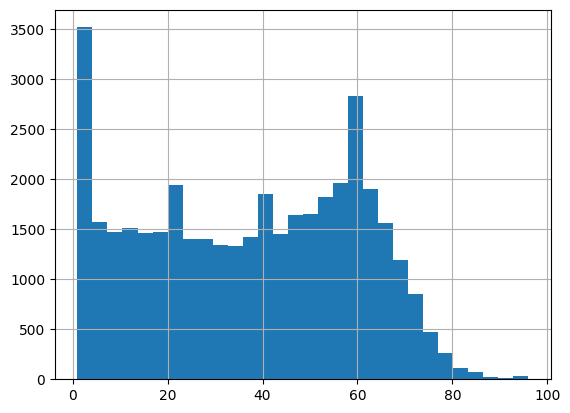

In [21]:
# histogram
df['snaps'].hist(bins=30)

In [22]:
pbp_data = []

In [35]:
df.tail()

,game_id,player_id,"offense_personnel_0 RB, 1 TE, 4 WR",qb_scramble,tackle_occurred,no_huddle,"offense_personnel_6 OL, 1 RB, 0 TE, 3 WR","offense_personnel_1 RB, 3 TE, 1 WR","offense_personnel_2 RB, 1 TE, 2 WR",run_location_middle,...,primary_injury_Neck,primary_injury_Quadricep,primary_injury_Shoulder,primary_injury_nan,secondary_injury_nan,status_Doubtful,status_Out,status_Questionable,status_nan,rare_injury
48700,NaN,00-0033831,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0,0,0,1,1,0,0,0,1,0
48701,NaN,00-0027029,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0,0,0,0,1,0,0,1,0,0
48702,NaN,00-0025708,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0,0,0,0,1,0,0,1,0,0
48703,NaN,00-0033386,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0,0,0,0,1,0,0,1,0,0
48704,NaN,00-0034319,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0,0,0,1,1,0,0,0,1,0


In [36]:
# Sort by game_id and play_id
df = df.sort_values(['season', 'week'])

grouped = df.groupby('player_id')

# Loop through to calculate rolling averages for each column
idx_cols = ['game_id', 'player_id', 'season', 'week', 'position_label', 'full_name']
for col in df.columns:
    if col not in idx_cols and pd.api.types.is_numeric_dtype(df[col]):
        df[f'rolling_{col}'] = grouped[col].transform(lambda x: x.rolling(window=3, min_periods=1).mean())

# Cumulative stats
df['cumulative_snaps'] = grouped['snaps'].cumsum()
df['cumulative_tackles'] = grouped['tackle_occurred'].cumsum()
df['cumulative_yards'] = grouped['yards_gained'].cumsum()
df['cumulative_pressure'] = grouped['was_pressure'].cumsum()
df['cumulative_time_to_throw'] = grouped['time_to_throw'].cumsum()
df['cumulative_air_yards'] = grouped['air_yards'].cumsum()
df['cumulative_xpass'] = grouped['xpass'].cumsum()
df['cumulative_qb_scramble'] = grouped['qb_scramble'].cumsum()
df['cumulative_no_huddle'] = grouped['no_huddle'].cumsum()
df['cumulative_shotgun'] = grouped['shotgun'].cumsum()
df['cumulative_yardline_100'] = grouped['yardline_100'].cumsum()

status_cols = df.columns[df.columns.str.contains('status')]
for col in status_cols:
    df[f'cumulative_{col}'] = grouped[col].cumsum()

# A. Workload Spike Feature (Acute-to-Chronic Workload Ratio Proxy)
# We assume the rolling window operates on plays, not games, given the original code structure.
# Acute (Short-term) window = 4 games/plays, Chronic (Long-term) window = 16 games/plays

short_window = 4
long_window = 16

df[f'rolling_sum_snaps_{short_window}'] = grouped['snaps'].transform(
    lambda x: x.rolling(window=short_window, min_periods=1).sum()
)

df[f'rolling_sum_snaps_{long_window}'] = grouped['snaps'].transform(
    lambda x: x.rolling(window=long_window, min_periods=1).sum()
)

# Load Spike: Ratio of short-term load (4 plays) to long-term load (16 plays)
# Add a small constant (1) to the denominator to prevent division by zero
df['snap_load_spike_ratio'] = df[f'rolling_sum_snaps_{short_window}'] / (df[f'rolling_sum_snaps_{long_window}'] + 1)


# B. Performance Trend (Decay/Decline)
# Rate of change in Expected Points Added (EPA) per snap over the last 3 plays/games.
if 'cumulative_snaps' in df.columns and 'cumulative_epa' in df.columns:
    df['cumulative_epa_per_snap'] = df['cumulative_epa'] / (df['cumulative_snaps'].replace(0, np.nan))

    # Calculate the change (delta) in the rolling mean EPA/Snap
    df['rolling_mean_epa_per_snap_3'] = grouped['cumulative_epa_per_snap'].transform(
        lambda x: x.rolling(window=3, min_periods=1).mean()
    )
    
    # Lag the rolling mean by 1 play to find the change from the previous play's average
    df['rolling_mean_epa_per_snap_lag_1'] = grouped['rolling_mean_epa_per_snap_3'].shift(1)
    
    # Performance Delta: Current rolling average minus the previous rolling average
    df['rolling_epa_decline_delta'] = df['rolling_mean_epa_per_snap_3'] - df['rolling_mean_epa_per_snap_lag_1']
    
    df = df.drop(columns=['rolling_mean_epa_per_snap_lag_1']) # Cleanup temp column


# C. Physical Load Interaction
# Cumulative load weighted by player mass (assumes 'weight' is available)
if 'weight' in df.columns:
    df['cumulative_snap_weight_load'] = df['cumulative_snaps'] * df['weight']


# D. Weighted Injury History (EWMA)
# Gives recent injury status exponential priority over older status.
# We use the maximum injury status (O=4, D=3, Q=2, P=1, None=0)
df['injury_status_risk'] = 0.0
if 'status_Out' in df.columns:
    df['injury_status_risk'] += df['status_Out'] * 4 
if 'status_Doubtful' in df.columns:
    df['injury_status_risk'] += df['status_Doubtful'] * 3
if 'status_Questionable' in df.columns:
    df['injury_status_risk'] += df['status_Questionable'] * 2
if 'status_Probable' in df.columns:
    df['injury_status_risk'] += df['status_Probable'] * 1

# Calculate EWMA, common alpha is between 0.9 and 0.95 for recent history
df['ewma_injury_risk'] = grouped['injury_status_risk'].transform(
    lambda x: x.ewm(span=14, adjust=False, min_periods=1).mean()
)

# E. Mass change
# Shows change in recent weight measurements
df['rolling_mean_weight_3'] = grouped['weight'].transform(
    lambda x: x.rolling(window=long_window, min_periods=1).mean()
)
df['weight_change'] = df['weight'] - df['rolling_mean_weight_3']

df = df.drop(columns=['injury_status_risk', 'rolling_mean_weight_3']) # Cleanup temp column

# --- 4. FINAL CLEANUP ---

# Drop the temporary rolling sum columns used for the spike ratio
df = df.drop(columns=[f'rolling_sum_snaps_{short_window}', f'rolling_sum_snaps_{long_window}'], errors='ignore')

df.tail()

,game_id,player_id,"offense_personnel_0 RB, 1 TE, 4 WR",qb_scramble,tackle_occurred,no_huddle,"offense_personnel_6 OL, 1 RB, 0 TE, 3 WR","offense_personnel_1 RB, 3 TE, 1 WR","offense_personnel_2 RB, 1 TE, 2 WR",run_location_middle,...,cumulative_status_Questionable,cumulative_status_nan,cumulative_rolling_status_Doubtful,cumulative_rolling_status_Out,cumulative_rolling_status_Questionable,cumulative_rolling_status_nan,snap_load_spike_ratio,cumulative_snap_weight_load,ewma_injury_risk,weight_change
39555,2019_21_SF_KC,00-0035148,0.0,1.0,2.0,0.0,0.0,0.0,0.0,1.0,...,0,14,0.0,0.0,0.0,14.0,0.256637,22400.0,0.000000,0.0
39556,2019_21_SF_KC,00-0035656,0.0,0.0,1.0,0.0,0.0,0.0,2.0,0.0,...,0,15,0.0,0.0,0.0,15.0,0.132492,102384.0,0.000000,0.0
39557,2019_21_SF_KC,00-0035717,0.0,4.0,4.0,5.0,0.0,0.0,0.0,8.0,...,3,16,0.0,0.0,4.0,15.0,0.259021,233016.0,0.202611,0.0
39558,2019_21_SF_KC,00-0035719,0.0,2.0,12.0,0.0,0.0,0.0,17.0,0.0,...,1,17,0.0,1.0,1.0,17.0,0.253968,173768.0,0.167876,0.0
48704,NaN,00-0034319,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0,8,0.0,0.0,0.0,8.0,0.794872,NaN,0.000000,NaN


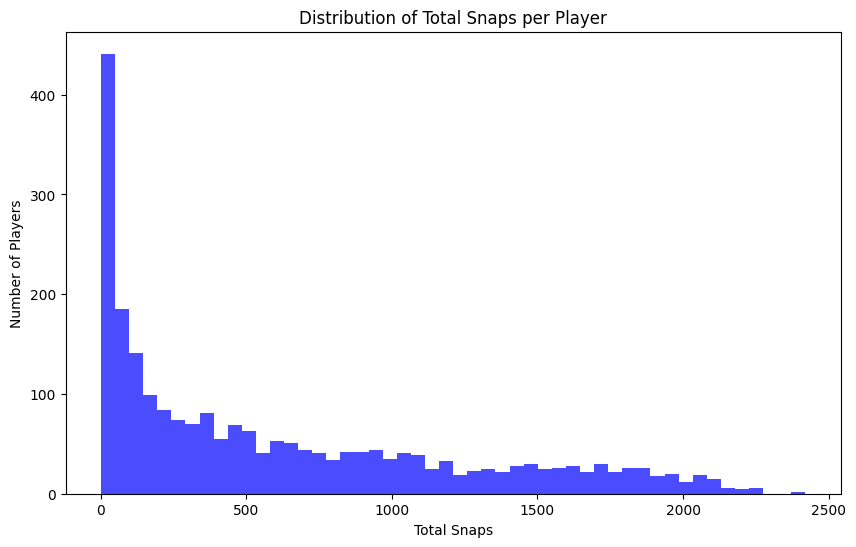

In [25]:
# Group by player_id to get total snaps per player
total_snaps = df.groupby('player_id')['cumulative_snaps'].max().reset_index()

# Plot histogram of total snaps
plt.figure(figsize=(10, 6))
plt.hist(total_snaps['cumulative_snaps'], bins=50, color='blue', alpha=0.7)
plt.title('Distribution of Total Snaps per Player')
plt.xlabel('Total Snaps')
plt.ylabel('Number of Players')
plt.show()

In [37]:
def get_position_groups(_):
    """
    Returns a dictionary with keys for 'offense', 'defense', and position groups,
    and values as lists of hard-coded position_labels.
    Ignores the input and uses a fixed list.
    """
    position_labels = [
        'C1', 'C2', 'C3', 'C4', 'CB1', 'CB2', 'CB3', 'CB4', 'CB5', 'CB6', 'CB7', 'CB8',
        'DE1', 'DE2', 'DE3', 'DE4', 'DE5', 'DE6', 'DE7', 'DT1', 'DT2', 'DT3', 'DT4', 'DT5', 'DT6', 'DT7',
        'FB1', 'FB2', 'FS1', 'FS2', 'FS3', 'FS4', 'ILB1', 'ILB2', 'ILB3', 'ILB4', 'ILB5', 'ILB6',
        'LG1', 'LG2', 'LG3', 'LT1', 'LT2', 'LT3', 'MLB1', 'MLB2', 'MLB3', 'NT1', 'NT2', 'NT3',
        'OLB1', 'OLB2', 'OLB3', 'OLB4', 'OLB5', 'OLB6', 'QB1', 'QB2', 'QB3', 'RB1', 'RB2', 'RB3', 'RB4', 'RB5',
        'RG1', 'RG2', 'RG3', 'RT1', 'RT2', 'RT3', 'SS1', 'SS2', 'SS3', 'SS4', 'SS5',
        'TE1', 'TE2', 'TE3', 'TE4', 'TE5', 'WR1', 'WR2', 'WR3', 'WR4', 'WR5', 'WR6', 'WR7', 'special1'
    ]

    group_dict = {
        'offense': [p for p in position_labels if any(p.startswith(x) for x in [
            'QB', 'RB', 'FB', 'WR', 'TE', 'LT', 'LG', 'C', 'RG', 'RT'])],
        'defense': [p for p in position_labels if any(p.startswith(x) for x in [
            'DE', 'DT', 'NT', 'OLB', 'ILB', 'MLB', 'CB', 'FS', 'SS'])],
        'qbs': [p for p in position_labels if p.startswith('QB')],
        'rbs': [p for p in position_labels if p.startswith('RB') or p.startswith('FB')],
        'tes': [p for p in position_labels if p.startswith('TE')],
        'wrs': [p for p in position_labels if p.startswith('WR')],
        'ol': [p for p in position_labels if p.startswith(('LT', 'LG', 'C', 'RG', 'RT')) and not p.startswith('CB')],
        'dl': [p for p in position_labels if p.startswith(('DE', 'DT', 'NT'))],
        'lbs': [p for p in position_labels if p.startswith(('OLB', 'ILB', 'MLB'))],
        'cbs': [p for p in position_labels if p.startswith('CB')],
        'ss': [p for p in position_labels if p.startswith(('SS', 'FS'))],
        'special': [p for p in position_labels if p.startswith('special')]
    }

    return group_dict

position_groups = get_position_groups(None)

# Create binary columns for each position group
for group, positions in position_groups.items():
    df[f'{group}'] = df['position_label'].isin(positions).astype(int)

# Prediction of Future Snaps

In [27]:
snap_counts = nfl.import_snap_counts(years=range(2016, 2026))

snap_counts = snap_counts.sort_values(['pfr_player_id', 'game_id'])

snap_counts['snap_count'] = snap_counts['offense_snaps'] + snap_counts['defense_snaps']

# Future cumulative snap counts by player_id (snaps from this game forward)
snap_counts['future_cumulative_snaps'] = snap_counts.groupby('pfr_player_id')['snap_count'].transform(
    lambda x: x[::-1].cumsum()[::-1]
)

In [31]:
# Top 10 players by max future cumulative snaps
(
    snap_counts.groupby('player', as_index=False)['future_cumulative_snaps']
    .max()
    .sort_values('future_cumulative_snaps', ascending=False)
    .head(10)
)

,player,future_cumulative_snaps
2902,Joe Thuney,12658.0
527,Bobby Wagner,11386.0
3488,Kevin Byard,11136.0
2499,Jake Matthews,10988.0
2636,Jared Goff,10607.0
3678,Lavonte David,10556.0
3509,Kevin Zeitler,10542.0
1620,Demario Davis,10530.0
5373,Travis Kelce,10400.0
2535,Jalen Ramsey,10373.0


Best iter: 411, Train RMSE: 1824.8011, Valid RMSE: 1797.6135
Best iter: 697, Train RMSE: 1807.1419, Valid RMSE: 1830.9231
Best iter: 754, Train RMSE: 1796.8512, Valid RMSE: 1854.2319
Best iter: 392, Train RMSE: 1815.0489, Valid RMSE: 1840.8036
Best iter: 505, Train RMSE: 1809.0306, Valid RMSE: 1848.2262
Train RMSE: 1809.031, R2: 0.191
Overall OOF RMSE: 1834.468, R2: 0.170
Top 10 XGB Feature Importances:
run_location_left                           0.376438
offense_personnel_2 QB, 1 RB, 1 TE, 2 WR    0.160745
yards_gained                                0.119526
offense_personnel_1 RB, 0 TE, 4 WR          0.070233
cumulative_shotgun                          0.053845
tackle_occurred                             0.025412
weight                                      0.015926
cumulative_yardline_100                     0.011858
age                                         0.008826
rolling_age                                 0.007880
dtype: float32


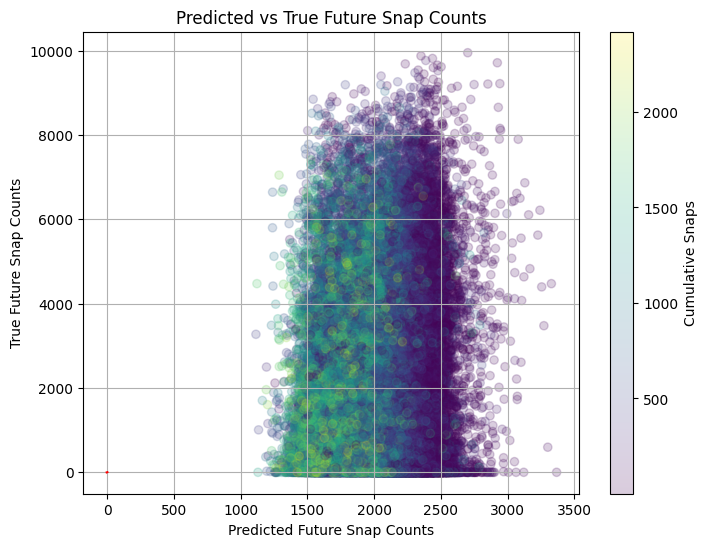

['C:\\Users\\Jack\\Documents\\GitHub\\FFInsights\\fatigue_snaps_model.pkl']

In [38]:
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error, r2_score
from xgboost import XGBRegressor

# Define future snap counts
y = df.merge(snap_counts[['game_id', 'player', 'future_cumulative_snaps']], left_on=['game_id', 'full_name'], right_on=['game_id', 'player'], how='left')['future_cumulative_snaps']

# Define features
X = df.drop(columns=idx_cols + ['residual_epa'])

oof_preds = np.zeros(len(X))
true_vals = np.zeros(len(X))

# ...existing code...
for train_idx, test_idx in KFold(n_splits=5, shuffle=True, random_state=999).split(X):
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

    xgb = XGBRegressor(
        n_estimators=1000,
        max_depth=4,
        learning_rate=0.01,
        reg_lambda=100,
        gamma=1.0,
        random_state=999
    )

    xgb.fit(
        X_train, y_train.fillna(0),
        eval_set=[(X_train, y_train.fillna(0)), (X_test, y_test.fillna(0))],
        eval_metric="rmse",
        early_stopping_rounds=50,
        verbose=False
    )

    # diagnostics
    evals = xgb.evals_result()
    train_rmse = np.array(evals["validation_0"]["rmse"])
    valid_rmse = np.array(evals["validation_1"]["rmse"])
    best_iter = xgb.best_iteration

    print(f"Best iter: {best_iter}, Train RMSE: {train_rmse[best_iter]:.4f}, Valid RMSE: {valid_rmse[best_iter]:.4f}")

    # optional: loss derivative (slope)
    train_slope = np.diff(train_rmse)
    valid_slope = np.diff(valid_rmse)

    xgb_preds_test = xgb.predict(X_test)
    xgb_preds_train = xgb.predict(X_train)

    oof_preds[test_idx] = xgb_preds_test
    true_vals[test_idx] = y_test.fillna(0)

print(f'Train RMSE: {mean_squared_error(y_train.fillna(0), xgb_preds_train, squared=False):.3f}, R2: {r2_score(y_train.fillna(0), xgb_preds_train):.3f}')
print(f'Overall OOF RMSE: {mean_squared_error(true_vals, oof_preds, squared=False):.3f}, R2: {r2_score(true_vals, oof_preds):.3f}')

expected_future_residual_epa_delta = pd.Series(oof_preds, index=X.index)

# XGB feature importance
xgb_importance = pd.Series(xgb.feature_importances_, index=X.columns)
xgb_importance = xgb_importance.loc[xgb_importance.sort_values(ascending=False).index]
print("Top 10 XGB Feature Importances:")
print(xgb_importance.head(10))

# Plot preds vs true
plt.figure(figsize=(8, 6))
plt.scatter(y=true_vals, x=oof_preds, c=df['cumulative_snaps'], cmap='viridis', alpha=0.20)
plt.colorbar(label='Cumulative Snaps')
plt.plot([-10, 10], [-10, 10], color='red', linestyle='--')
plt.ylabel('True Future Snap Counts')
plt.xlabel('Predicted Future Snap Counts')
plt.title('Predicted vs True Future Snap Counts')
plt.grid(True)
plt.show()

# Save model
import joblib
joblib.dump(xgb, r'C:\Users\Jack\Documents\GitHub\FFInsights\fatigue_snaps_model.pkl')

# Prediction of Delta EPA

Train RMSE: 1.041, R2: 0.690
Overall OOF RMSE: 1.287, R2: 0.526
Top 10 XGB Feature Importances:
rolling_yards_gained                  0.043661
rolling_residual_epa                  0.036887
offense_personnel_2 RB, 0 TE, 3 WR    0.030783
yards_gained                          0.030604
cumulative_rolling_status_nan         0.023918
cumulative_time_to_throw              0.023510
snap_load_spike_ratio                 0.022127
rolling_primary_injury_Calf           0.021414
cumulative_yards                      0.019767
cumulative_yardline_100               0.019083
dtype: float32


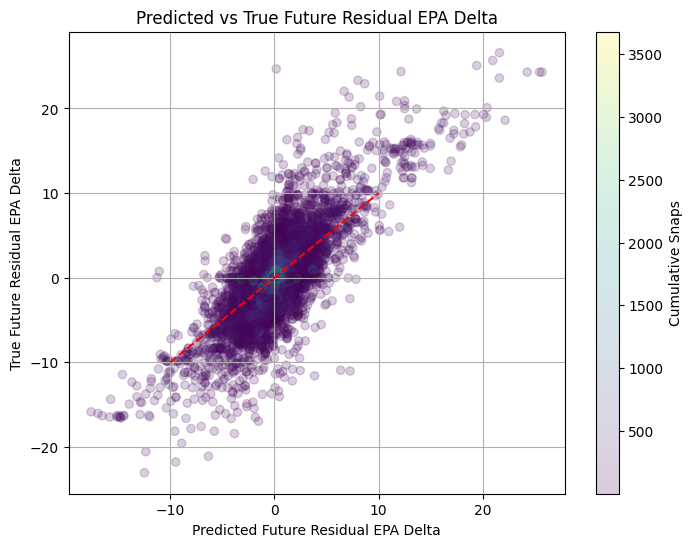

['C:\\Users\\Jack\\Documents\\GitHub\\FFInsights\\fatigue_epa_model.pkl']

In [31]:
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error, r2_score
from xgboost import XGBRegressor

# Define future residual_epa average
ftr_epa_avg = df.groupby('player_id')['residual_epa'].transform(lambda x: x.expanding(min_periods=1).mean().shift(-1))
cmltv_epa_avg = df.groupby('player_id')['residual_epa'].transform(lambda x: x.expanding(min_periods=1).mean().shift(1)) # Cumulative average
y = ftr_epa_avg - cmltv_epa_avg

# Define features
X = df.drop(columns=idx_cols + ['residual_epa'])

oof_preds = np.zeros(len(X))
true_vals = np.zeros(len(X))

for train_idx, test_idx in KFold(n_splits=5, shuffle=True, random_state=999).split(X):
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

    xgb = XGBRegressor(n_estimators=1000, max_depth=4, learning_rate=0.05, reg_lambda=0.75, gamma=1.0, random_state=999)
    xgb.fit(X_train, y_train.fillna(0))
    xgb_preds_test = xgb.predict(X_test)
    xgb_preds_train = xgb.predict(X_train)

    oof_preds[test_idx] = xgb_preds_test
    true_vals[test_idx] = y_test.fillna(0)

print(f'Train RMSE: {mean_squared_error(y_train.fillna(0), xgb_preds_train, squared=False):.3f}, R2: {r2_score(y_train.fillna(0), xgb_preds_train):.3f}')
print(f'Overall OOF RMSE: {mean_squared_error(true_vals, oof_preds, squared=False):.3f}, R2: {r2_score(true_vals, oof_preds):.3f}')

expected_future_residual_epa_delta = pd.Series(oof_preds, index=X.index)

# XGB feature importance
xgb_importance = pd.Series(xgb.feature_importances_, index=X.columns)
xgb_importance = xgb_importance.loc[xgb_importance.sort_values(ascending=False).index]
print("Top 10 XGB Feature Importances:")
print(xgb_importance.head(10))

# Plot preds vs true
plt.figure(figsize=(8, 6))
plt.scatter(y=true_vals, x=oof_preds, c=df['cumulative_snaps'], cmap='viridis', alpha=0.20)
plt.colorbar(label='Cumulative Snaps')
plt.plot([-10, 10], [-10, 10], color='red', linestyle='--')
plt.ylabel('True Future Residual EPA Delta')
plt.xlabel('Predicted Future Residual EPA Delta')
plt.title('Predicted vs True Future Residual EPA Delta')
plt.grid(True)
plt.show()

# Save model
import joblib
joblib.dump(xgb, r'C:\Users\Jack\Documents\GitHub\FFInsights\fatigue_epa_model.pkl')

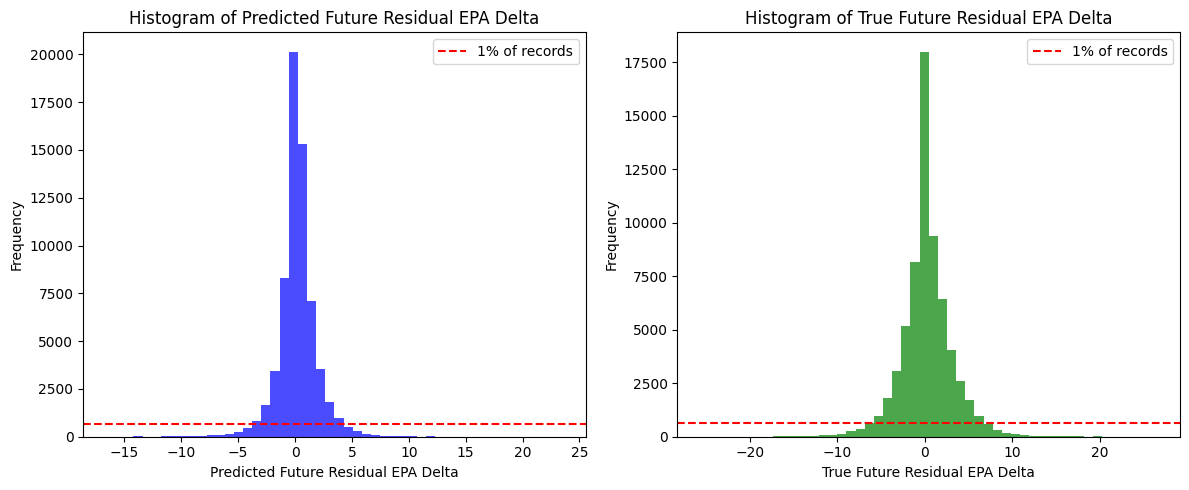

In [25]:
# Calculate 1% of total records
one_percent = len(df) * 0.01

# Histogram of oof_preds and true_vals
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.hist(oof_preds, bins=50, color='blue', alpha=0.7)
plt.axhline(one_percent, color='red', linestyle='--', label='1% of records')
plt.legend()
plt.title('Histogram of Predicted Future Residual EPA Delta')
plt.xlabel('Predicted Future Residual EPA Delta')
plt.ylabel('Frequency')
#plt.yscale('log')

plt.subplot(1, 2, 2)
plt.hist(true_vals, bins=50, color='green', alpha=0.7)
plt.axhline(one_percent, color='red', linestyle='--', label='1% of records')
plt.legend()
plt.title('Histogram of True Future Residual EPA Delta')
plt.xlabel('True Future Residual EPA Delta')
plt.ylabel('Frequency')
#plt.yscale('log')

plt.tight_layout()
plt.show()

# Prediction of Injury Length

Train RMSE: 0.045, R2: 0.784
Overall OOF RMSE: 0.045, R2: 0.781
Top 10 XGB Feature Importances:
rolling_status_Out                        0.255672
ewma_injury_risk                          0.204581
cumulative_rolling_status_Out             0.121270
cumulative_status_nan                     0.090896
cumulative_status_Out                     0.070254
cumulative_rolling_status_nan             0.057159
cumulative_rolling_status_Questionable    0.033161
snap_load_spike_ratio                     0.032147
status_Out                                0.031163
cumulative_yards                          0.027057
dtype: float32


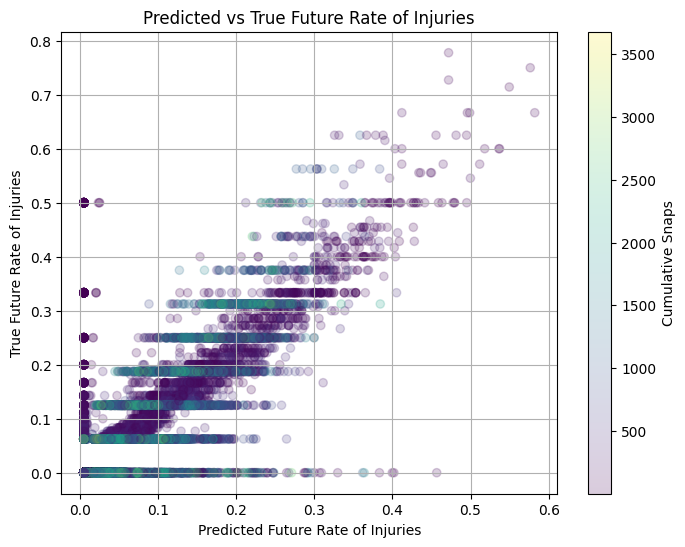

['C:\\Users\\Jack\\Documents\\GitHub\\FFInsights\\fatigue_injury_rate_model.pkl']

In [26]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error, r2_score
from xgboost import XGBRegressor

# Define future rate of injuries
y = df.groupby('player_id')['status_Out'].transform(lambda x: x.rolling(window=16, min_periods=1).mean().shift(-1))

# Define features
X = df.drop(columns=idx_cols + ['residual_epa'])

oof_preds = np.zeros(len(X))
true_vals = np.zeros(len(X))

for train_idx, test_idx in KFold(n_splits=5, shuffle=True, random_state=999).split(X):
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

    xgb = XGBRegressor(n_estimators=1000, max_depth=4, learning_rate=0.05, reg_lambda=0.75, gamma=1.0, random_state=999)
    xgb.fit(X_train, y_train.fillna(0))
    xgb_preds_test = xgb.predict(X_test)
    xgb_preds_train = xgb.predict(X_train)

    oof_preds[test_idx] = xgb_preds_test
    true_vals[test_idx] = y_test.fillna(0)

print(f'Train RMSE: {mean_squared_error(y_train.fillna(0), xgb_preds_train, squared=False):.3f}, R2: {r2_score(y_train.fillna(0), xgb_preds_train):.3f}')
print(f'Overall OOF RMSE: {mean_squared_error(true_vals, oof_preds, squared=False):.3f}, R2: {r2_score(true_vals, oof_preds):.3f}')

expected_future_injury_rate = pd.Series(oof_preds, index=X.index)

# XGB feature importance
xgb_importance = pd.Series(xgb.feature_importances_, index=X.columns)
xgb_importance = xgb_importance.loc[xgb_importance.sort_values(ascending=False).index]
print("Top 10 XGB Feature Importances:")
print(xgb_importance.head(10))

# Plot preds vs true
plt.figure(figsize=(8, 6))
plt.scatter(y=true_vals, x=oof_preds, c=df['cumulative_snaps'], cmap='viridis', alpha=0.20)
plt.colorbar(label='Cumulative Snaps')
#plt.plot([-1, 1], [-1, 1], color='red', linestyle='--')
plt.ylabel('True Future Rate of Injuries')
plt.xlabel('Predicted Future Rate of Injuries')
plt.title('Predicted vs True Future Rate of Injuries')
plt.grid(True)
plt.show()

# Save model
import joblib
joblib.dump(xgb, r'C:\Users\Jack\Documents\GitHub\FFInsights\fatigue_injury_rate_model.pkl')

In [27]:
injuries['report_status'].value_counts()

Questionable    4179
Out             2853
Doubtful         517
Name: report_status, dtype: int64

## Prediction of Recovery Elasticity

Train RMSE: 4.061, R2: 0.511
Overall OOF RMSE: 4.499, R2: 0.399
Top 10 XGB Feature Importances:
yards_gained                     0.071069
xpass                            0.027913
play_type_run                    0.025525
cumulative_rolling_status_nan    0.018535
cumulative_yardline_100          0.018444
cumulative_xpass                 0.017794
yardline_100                     0.017162
cumulative_yards                 0.016356
rolling_residual_epa             0.016328
snaps                            0.015627
dtype: float32


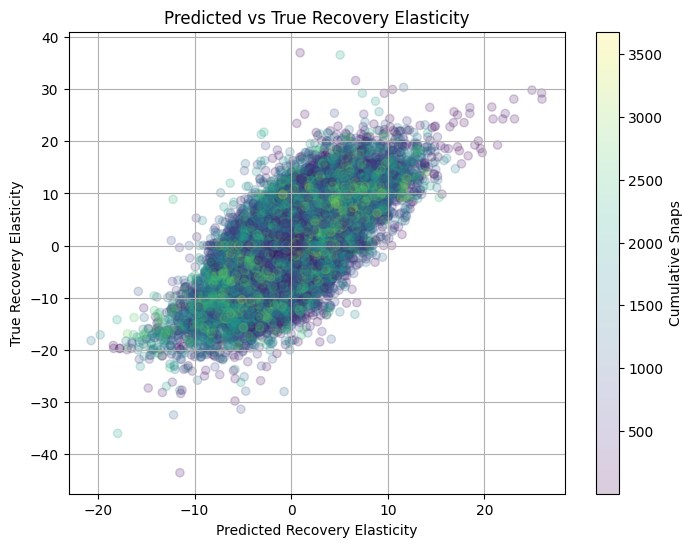

['C:\\Users\\Jack\\Documents\\GitHub\\FFInsights\\fatigue_recovery_elasticity_model.pkl']

In [29]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error, r2_score
from xgboost import XGBRegressor

# Define recovery elasticity
baseline = df.groupby('player_id')['residual_epa'].transform(lambda x: x.rolling(window=8, min_periods=1).mean().shift(1)) # Last 8 games average
next_three_games = df.groupby('player_id')['residual_epa'].transform(lambda x: x.rolling(window=3, min_periods=1).mean().shift(-1))
y = next_three_games - baseline

# Define features
X = df.drop(columns=idx_cols + ['residual_epa'])

oof_preds = np.zeros(len(X))
true_vals = np.zeros(len(X))

for train_idx, test_idx in KFold(n_splits=5, shuffle=True, random_state=999).split(X):
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

    xgb = XGBRegressor(n_estimators=1000, max_depth=4, learning_rate=0.05, reg_lambda=0.75, gamma=1.0, random_state=999)
    xgb.fit(X_train, y_train.fillna(0))
    xgb_preds_test = xgb.predict(X_test)
    xgb_preds_train = xgb.predict(X_train)

    oof_preds[test_idx] = xgb_preds_test
    true_vals[test_idx] = y_test.fillna(0)

print(f'Train RMSE: {mean_squared_error(y_train.fillna(0), xgb_preds_train, squared=False):.3f}, R2: {r2_score(y_train.fillna(0), xgb_preds_train):.3f}')
print(f'Overall OOF RMSE: {mean_squared_error(true_vals, oof_preds, squared=False):.3f}, R2: {r2_score(true_vals, oof_preds):.3f}')

expected_recovery_elasticity = pd.Series(oof_preds, index=X.index)

# XGB feature importance
xgb_importance = pd.Series(xgb.feature_importances_, index=X.columns)
xgb_importance = xgb_importance.loc[xgb_importance.sort_values(ascending=False).index]
print("Top 10 XGB Feature Importances:")
print(xgb_importance.head(10))

# Plot preds vs true
plt.figure(figsize=(8, 6))
plt.scatter(y=true_vals, x=oof_preds, c=df['cumulative_snaps'], cmap='viridis', alpha=0.20)
plt.colorbar(label='Cumulative Snaps')
#plt.plot([-1, 1], [-1, 1], color='red', linestyle='--')
plt.ylabel('True Recovery Elasticity')
plt.xlabel('Predicted Recovery Elasticity')
plt.title('Predicted vs True Recovery Elasticity')
plt.grid(True)
plt.show()

# Save model
import joblib
joblib.dump(xgb, r'C:\Users\Jack\Documents\GitHub\FFInsights\fatigue_recovery_elasticity_model.pkl')